# 02 - Séparation train / test par chien

**Parti pris central du projet** : le split se fait **par chien**. Toutes les données d'un chien sont soit
en apprentissage, soit en test. Les fenêtres voisines d'un même chien sont très corrélées (et se
chevauchent) : un split aléatoire par fenêtre mettrait des quasi-doublons de part et d'autre et gonflerait
artificiellement les scores. Le score de test mesure ainsi la capacité à **généraliser à un chien jamais vu**.

Le split est enregistré dans `data/processed/split.json` et réutilisé par tous les notebooks suivants.

In [1]:
import sys
from pathlib import Path

# Racine du projet ajoutée au chemin d'import (le notebook est dans notebooks/)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

from src import data, viz

In [2]:
moves = data.load_moves(columns=["DogID", "TestNum", "Behavior_1"])
dogs = data.load_dogs()

annotated_dogs = moves.dropna(subset=["Behavior_1"])["DogID"].unique()
train_ids, test_ids = data.split_dogs(annotated_dogs, test_size=cfg.TEST_SIZE, seed=cfg.SPLIT_SEED)
data.save_split(train_ids, test_ids)
print(f"Train : {len(train_ids)} chiens | Test : {len(test_ids)} chiens")
print("Chiens de test :", test_ids)

Train : 36 chiens | Test : 9 chiens
Chiens de test : [16, 30, 33, 34, 41, 55, 70, 73, 74]


## Représentativité du test

Avec ~9 chiens de test, le hasard du split compte beaucoup. On vérifie que le test ressemble au train
(comportements, profils). L'effet du choix de la graine sur le score sera mesuré au notebook 04
(analyse de sensibilité) : il n'est pas question de « choisir la graine qui donne le meilleur score ».

Set,Test,Train
Behavior_1,,
Sniffing,14.97,15.85
Lying chest,15.81,15.71
Panting,9.52,13.70
Playing,13.83,12.96
Trotting,9.96,11.23
Walking,11.67,10.95
Sitting,11.07,6.80
Standing,7.96,6.52
Eating,1.05,2.97


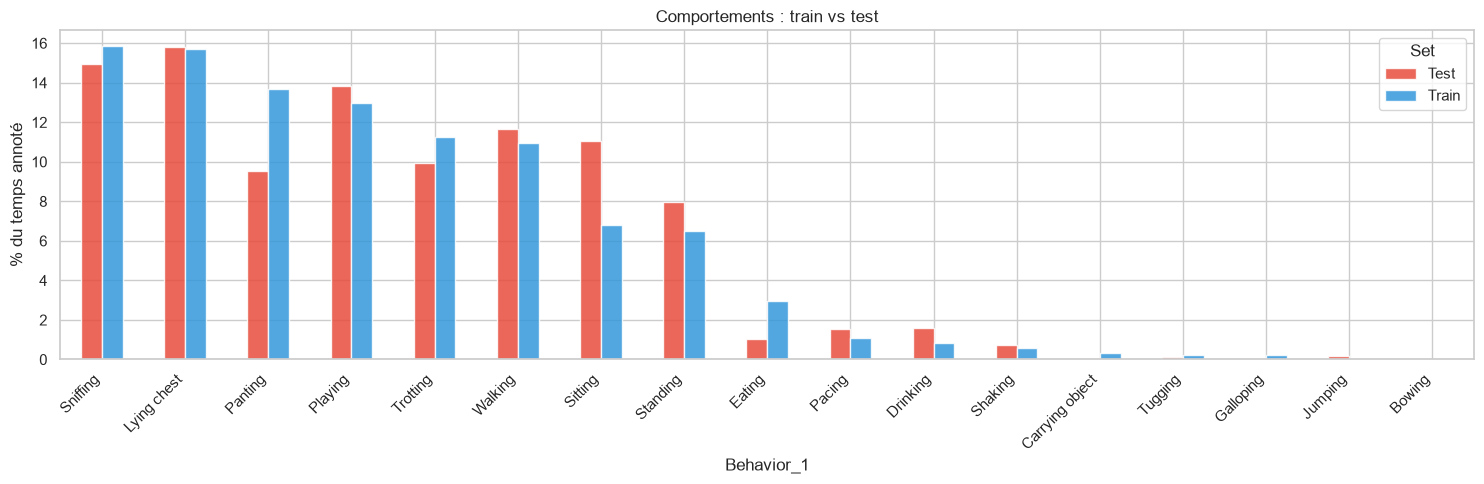

Comportements absents du test : ['Galloping', 'Bowing']


In [3]:
moves["Set"] = np.where(moves["DogID"].isin(test_ids), "Test", "Train")
prop = (moves.dropna(subset=["Behavior_1"]).groupby("Set")["Behavior_1"]
        .value_counts(normalize=True).mul(100).unstack(0).fillna(0).sort_values("Train", ascending=False))
display(prop.round(2))
ax = prop.plot.bar(figsize=(15, 5), color=["#e74c3c", "#3498db"], alpha=0.85)
ax.set_ylabel("% du temps annoté"); ax.set_title("Comportements : train vs test")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); viz.savefig(ax.figure, "02_classes_train_test"); plt.show()

absent_test = prop.index[prop["Test"] == 0].tolist()
print("Comportements absents du test :", absent_test or "aucun")

Age months                Weight             
            mean   std min  max   mean  std min max
Set                                                
Test        53.6  31.3  20   98   21.8  5.5  13  32
Train       59.2  29.1  16  116   24.8  7.2  13  41

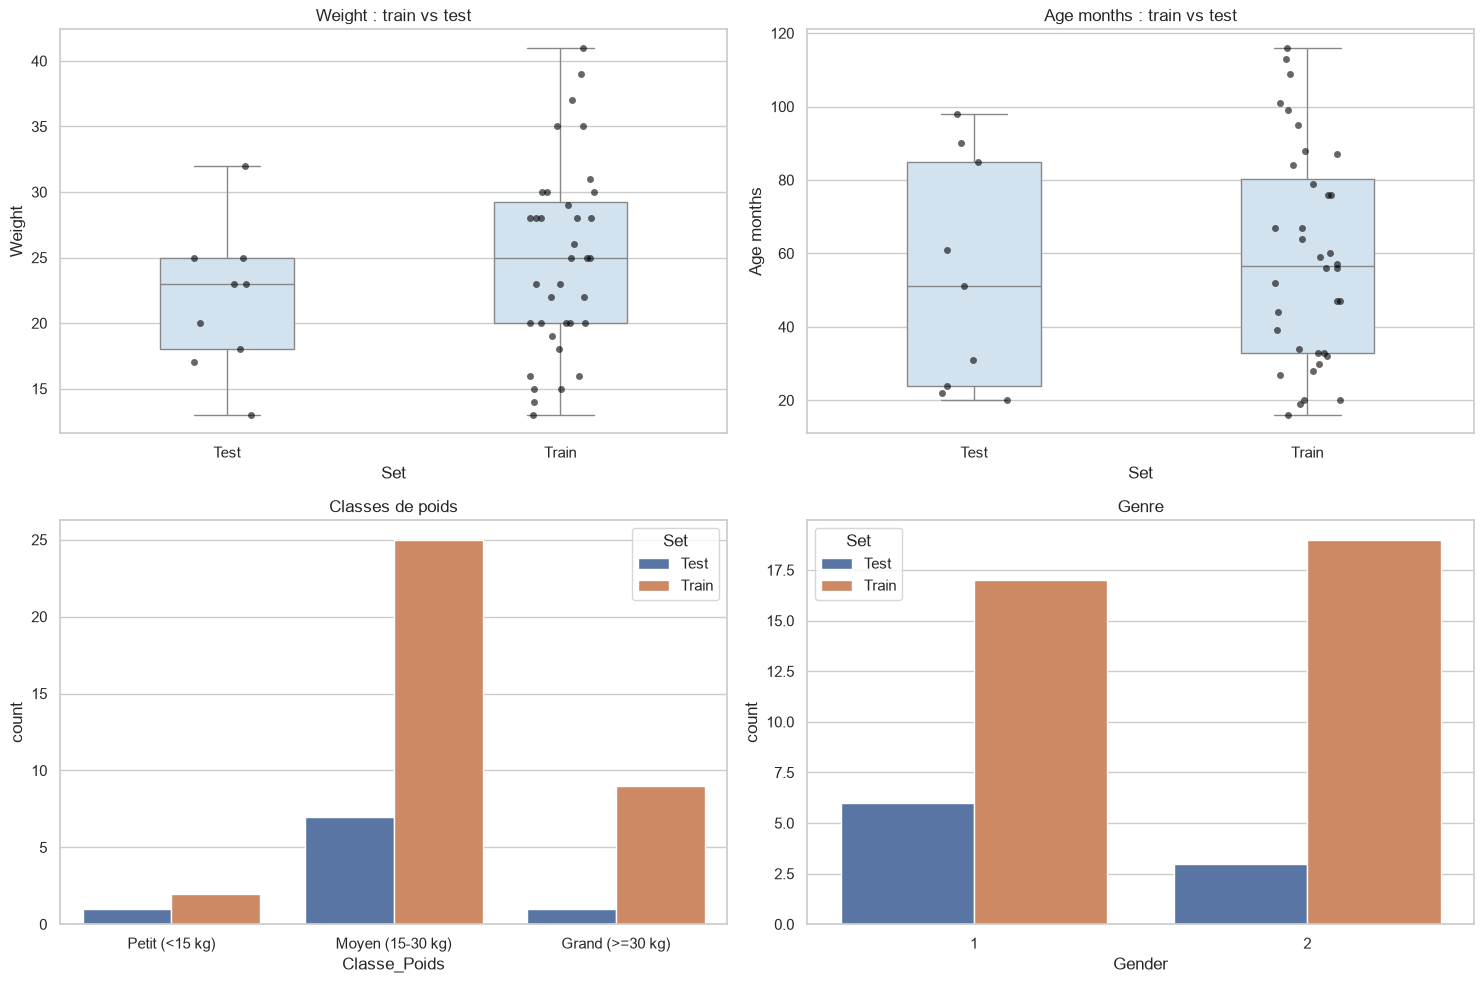

In [4]:
d = dogs[dogs["DogID"].isin(list(train_ids) + list(test_ids))].copy()
d["Set"] = np.where(d["DogID"].isin(test_ids), "Test", "Train")
display(d.groupby("Set")[["Age months", "Weight"]].agg(["mean", "std", "min", "max"]).round(1))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes[0], ["Weight", "Age months"]):
    sns.boxplot(data=d, x="Set", y=col, ax=ax, width=0.4, color="#cfe2f3")
    sns.stripplot(data=d, x="Set", y=col, ax=ax, color="black", alpha=0.6)
    ax.set_title(f"{col} : train vs test")
sns.countplot(data=d, x="Classe_Poids", hue="Set", ax=axes[1, 0]); axes[1, 0].set_title("Classes de poids")
sns.countplot(data=d, x="Gender", hue="Set", ax=axes[1, 1]); axes[1, 1].set_title("Genre")
plt.tight_layout(); viz.savefig(fig, "02_profils_train_test"); plt.show()